# **Minecraft Mosaic Generator: Parallel Computing Benchmark**

# Section 1: Environment Setup & Data Loading

This cell connects your Colab instance to your Google Drive (where your texture zip file or image folders live) and imports the standard scientific Python stack.

In [ ]:
# 1.1 MOUNT DRIVE & IMPORT CORE LIBRARIES

import os
import sys
import glob
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

print("Google Drive mounted successfully.")
print(f"Python Version: {sys.version.split()[0]}")
print(f"NumPy Version: {np.__version__}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive mounted successfully.
Python Version: 3.13.16
NumPy Version: 2.4.6


In [ ]:
!ls /usr/lib/jvm/


java-1.21.0-openjdk-amd64  java-21-openjdk-amd64


To satisfy the Week 9–10 (Spark) syllabus requirements without setting up an external Linux/Hadoop cluster, we install pyspark and Java OpenJDK directly inside Colab. This creates an in-memory local Spark cluster (local[*]).

In [ ]:
# 1.2 INSTALL & INITIALIZE PYSPARK

import os
import sys

# 1. Force the system to point to Java 21
!update-alternatives --set java /usr/lib/jvm/java-21-openjdk-amd64/bin/java

# Verify it registers version "21.x"
!java -version

# 2. Re-bind the environment variables to Java 21
os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-21-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

# 3. Add explicit Java 21 garbage collection options to prevent JVM initialization crashes
java_21_opts = (
    "-XX:+IgnoreUnrecognizedVMOptions "
    "--add-opens=java.base/java.lang=ALL-UNNAMED "
    "--add-opens=java.base/java.lang.invoke=ALL-UNNAMED "
    "--add-opens=java.base/java.reflect=ALL-UNNAMED "
    "--add-opens=java.base/java.io=ALL-UNNAMED "
    "--add-opens=java.base/java.net=ALL-UNNAMED "
    "--add-opens=java.base/java.nio=ALL-UNNAMED "
    "--add-opens=java.base/java.util=ALL-UNNAMED "
    "--add-opens=java.base/java.util.concurrent=ALL-UNNAMED "
    "--add-opens=java.base/java.util.concurrent.atomic=ALL-UNNAMED "
    "--add-opens=java.base/sun.nio.ch=ALL-UNNAMED "
    "--add-opens=java.base/sun.nio.cs=ALL-UNNAMED "
    "--add-opens=java.base/sun.security.action=ALL-UNNAMED "
    "--add-opens=java.util/java.util=ALL-UNNAMED "
    "-Djava.security.manager=allow"
)

os.environ["PYSPARK_SUBMIT_ARGS"] = f'--driver-java-options "{java_21_opts}" pyspark-shell'

# 4. Initialize the session securely
from pyspark.sql import SparkSession

try:
    spark = SparkSession.builder \
        .master("local[*]") \
        .appName("ColabUbuntu2404Java21") \
        .config("spark.driver.extraJavaOptions", java_21_opts) \
        .config("spark.executor.extraJavaOptions", java_21_opts) \
        .getOrCreate()
    print("\n🎉 Success! Your Spark Session is fully working with Java 21!")
except Exception as e:
    print(f"\n❌ Persistent issue: {e}")


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)

🎉 Success! Your Spark Session is fully working with Java 21!


Place your texture zip file (or folder) and target image inside your Drive folder, then set the paths below to extract them to Colab's local high-speed SSD (/content/).

In [ ]:
# 1.3 UNZIP DATASETS TO LOCAL COLAB STORAGE

# Update these paths to match your Google Drive location
DRIVE_ZIP_PATH = "/content/drive/MyDrive/minecraft_textures.zip"
LOCAL_EXTRACT_DIR = "/content/minecraft_textures"

# Unzip textures if not already extracted
if os.path.exists(DRIVE_ZIP_PATH):
    print(f"Extracting textures from Drive: {DRIVE_ZIP_PATH}...")
    with zipfile.ZipFile(DRIVE_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_EXTRACT_DIR)
    print("Extraction complete!")
else:
    print(f"ZIP file not found at {DRIVE_ZIP_PATH}. Creating empty directory for testing.")
    os.makedirs(LOCAL_EXTRACT_DIR, exist_ok=True)

# Count raw PNG files extracted
raw_png_count = len(glob.glob(os.path.join(LOCAL_EXTRACT_DIR, "**", "*.png"), recursive=True))
print(f"Total raw PNG textures found in local storage: {raw_png_count}")

Extracting textures from Drive: /content/drive/MyDrive/minecraft_textures.zip...
Extraction complete!
Total raw PNG textures found in local storage: 1133


# Section 2: Dataset Preprocessing & Feature Extraction

This function iterates through your extracted texture directory, filters out transparent items, animated sheets, and non-solid blocks, and standardizes everything to $16\times16$ RGB matrices.

In [ ]:
# ==========================================
# 2.1 TEXTURE DATASET CLEANING & FILTERING
# ==========================================
import os
import glob
import numpy as np
from PIL import Image

def preprocess_minecraft_textures(textures_dir, target_size=(16, 16)):
    """
    Filters non-solid, transparent, and non-standard textures.
    Returns clean image file paths and their mean RGB vectors.
    """
    valid_paths = []
    valid_features = []

    # Exclude non-solid or UI element filenames
    SKIP_KEYWORDS = [
        "candle", "torch", "rail", "ladder", "door", "banner",
        "flower", "sapling", "coral", "wheat", "carrots", "destroy",
        "pattern", "breaking", "gui", "particle", "glass_pane", "bed"
    ]

    all_pngs = glob.glob(os.path.join(textures_dir, "**", "*.png"), recursive=True)
    print(f"Scanning {len(all_pngs)} raw PNG files...")

    for file_path in all_pngs:
        filename = os.path.basename(file_path).lower()

        # 1. Skip non-solid block keywords
        if any(keyword in filename for keyword in SKIP_KEYWORDS):
            continue

        try:
            with Image.open(file_path) as img:
                w, h = img.size

                # 2. Handle animated textures (crop top 16x16 frame from tall sprite sheets)
                if w == target_size[0] and h > target_size[1]:
                    img = img.crop((0, 0, target_size[0], target_size[1]))
                    w, h = img.size

                # 3. Enforce exact 16x16 dimensions
                if (w, h) != target_size:
                    continue

                # 4. Check alpha channel for transparency
                img_rgba = img.convert("RGBA")
                arr_rgba = np.array(img_rgba)
                alpha_channel = arr_rgba[:, :, 3]

                # Reject if any pixel is transparent
                if np.any(alpha_channel < 255):
                    continue

                # 5. Extract mean RGB feature vector
                img_rgb = img_rgba.convert("RGB")
                arr_rgb = np.array(img_rgb)
                mean_rgb = arr_rgb.mean(axis=(0, 1)) # Shape: (3,)

                valid_paths.append(file_path)
                valid_features.append(mean_rgb)

        except Exception:
            continue

    valid_features = np.array(valid_features)
    print(f"✅ Filtered down to {len(valid_paths)} solid, valid 16x16 block textures.")
    return valid_paths, valid_features

# Run preprocessing
block_paths, block_features = preprocess_minecraft_textures("/content/minecraft_textures")

Scanning 1133 raw PNG files...
✅ Filtered down to 641 solid, valid 16x16 block textures.


This cell loads your target photo, crops it into a uniform grid of $16\times16$ tiles, and calculates each tile's mean RGB color.

In [ ]:
# ==========================================
# 2.2 TARGET IMAGE SLICING & PATCHING
# ==========================================
def prepare_target_tiles(image_path, tile_size=16):
    """
    Slices a high-resolution target image into 16x16 patches.
    Returns array of mean RGB vectors per tile and grid dimensions (rows, cols).
    """
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img_arr = np.array(img)

    height, width, _ = img_arr.shape
    n_rows = height // tile_size
    n_cols = width // tile_size

    tiles_rgb = []

    for r in range(n_rows):
        for c in range(n_cols):
            row_s, row_e = r * tile_size, (r + 1) * tile_size
            col_s, col_e = c * tile_size, (c + 1) * tile_size

            tile_patch = img_arr[row_s:row_e, col_s:col_e]
            tiles_rgb.append(tile_patch.mean(axis=(0, 1)))

    tiles_rgb = np.array(tiles_rgb)
    print(f"✅ Target image sliced successfully!")
    print(f"Grid dimensions: {n_rows} rows x {n_cols} cols")
    print(f"Total tiles to match: {len(tiles_rgb)}")
    return tiles_rgb, (n_rows, n_cols)

# Replace with your target image filename in Colab
TARGET_IMAGE_PATH = "/content/drive/MyDrive/target_image.png"

TILE_SIZE=16

# 1. Load image and convert to standard RGB (strips unexpected alpha channel issues)
img = Image.open(TARGET_IMAGE_PATH).convert("RGB")

# 2. Calculate exact dimensions divisible by TILE_SIZE (16)
w, h = img.size
new_w = (w // TILE_SIZE) * TILE_SIZE
new_h = (h // TILE_SIZE) * TILE_SIZE

# 3. Crop to the valid grid boundary
img = img.crop((0, 0, new_w, new_h))

print(f"Original Size: ({w}, {h}) -> Adjusted Clean Grid Size: ({new_w}, {new_h})")

# Fallback: Generate a sample target image if file doesn't exist yet
if not os.path.exists(TARGET_IMAGE_PATH):
    dummy_img = Image.fromarray(np.random.randint(0, 256, (640, 640, 3), dtype=np.uint8))
    dummy_img.save(TARGET_IMAGE_PATH)
    print(f"Sample target image created at {TARGET_IMAGE_PATH}")

target_tiles_rgb, grid_shape = prepare_target_tiles(TARGET_IMAGE_PATH, tile_size=16)

Original Size: (4224, 3363) -> Adjusted Clean Grid Size: (4224, 3360)
✅ Target image sliced successfully!
Grid dimensions: 210 rows x 264 cols
Total tiles to match: 55440


# Section 3: Baseline Implementation (Single-Threaded Sequential Loops)

This cell loops through every target tile one by one, finds the closest matching block texture, and records detailed execution metrics.

In [ ]:
# ==========================================
# 3.1 SINGLE-THREADED SEQUENTIAL BASELINE
# ==========================================
import time
import numpy as np

def run_baseline_sequential(target_tiles, block_library):
    """
    Sequential single-threaded matching using Euclidean distance.
    Computes distance between each tile vector and all block library vectors.
    """
    start_time = time.time()
    matched_indices = []

    # Sequential loop over target tiles
    for tile in target_tiles:
        # Euclidean distance across 3D RGB color space: sqrt(sum((A - B)^2))
        distances = np.linalg.norm(block_library - tile, axis=1)
        best_match_idx = np.argmin(distances)
        matched_indices.append(best_match_idx)

    execution_time = time.time() - start_time
    return matched_indices, execution_time

# Run the single-threaded baseline benchmark
print("Running Single-Threaded Baseline...")
baseline_indices, baseline_time = run_baseline_sequential(target_tiles_rgb, block_features)

# Calculate throughput metrics
total_tiles = len(target_tiles_rgb)
tiles_per_sec = total_tiles / baseline_time

print("=" * 45)
print("📊 BASELINE PERFORMANCE RESULTS")
print("=" * 45)
print(f"Total Tiles Processed : {total_tiles} ({grid_shape[0]}x{grid_shape[1]} grid)")
print(f"Block Library Size    : {len(block_features)} textures")
print(f"Sequential Runtime    : {baseline_time:.4f} seconds")
print(f"Throughput Rate       : {tiles_per_sec:.2f} tiles/sec")
print("=" * 45)

Running Single-Threaded Baseline...
📊 BASELINE PERFORMANCE RESULTS
Total Tiles Processed : 55440 (210x264 grid)
Block Library Size    : 641 textures
Sequential Runtime    : 1.6828 seconds
Throughput Rate       : 32944.24 tiles/sec


This cell maps the matched block indices back to their $16\times16$ texture images, stiches them together into the final Minecraft mosaic image, and displays a side-by-side comparison with your original photo.

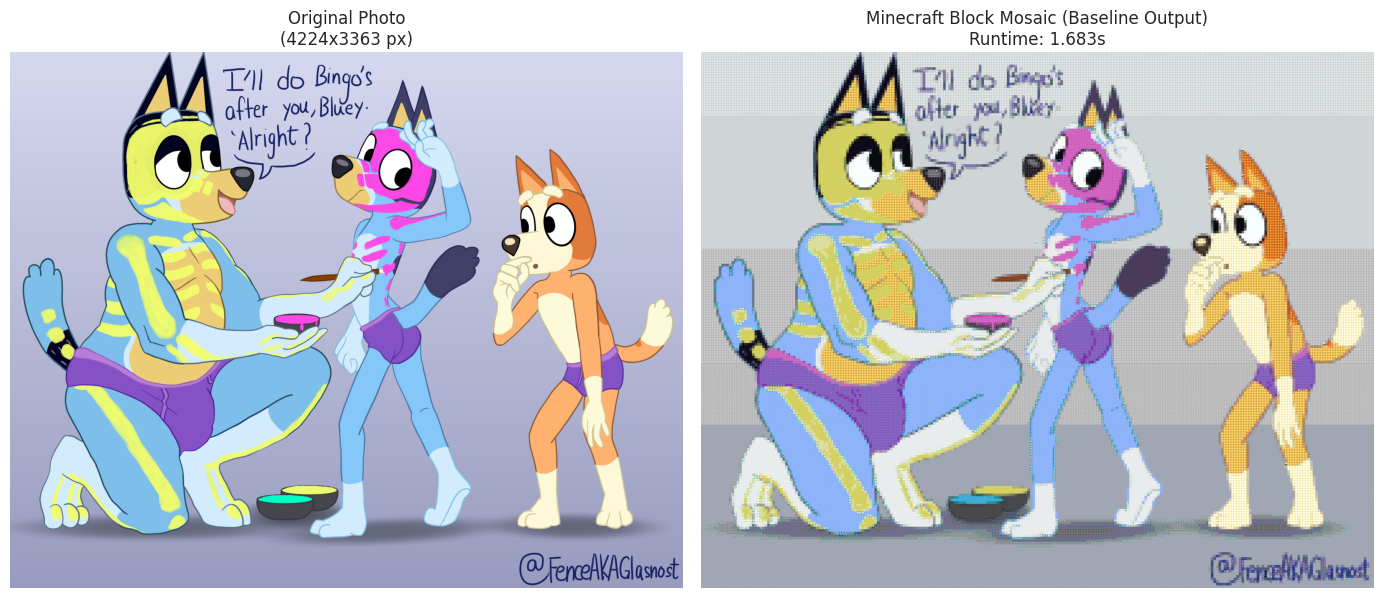

✅ Output image saved to /content/mosaic_baseline_output.png


In [ ]:
# ==========================================
# 3.2 RECONSTRUCT & RENDER MOSAIC
# ==========================================
import matplotlib.pyplot as plt
from PIL import Image

def reconstruct_mosaic(matched_indices, block_paths, grid_shape, tile_size=16):
    """
    Stitches selected 16x16 block texture images together into the final mosaic canvas.
    """
    n_rows, n_cols = grid_shape
    canvas_w = n_cols * tile_size
    canvas_h = n_rows * tile_size

    # Create empty RGB canvas
    mosaic_img = Image.new("RGB", (canvas_w, canvas_h))

    # Cache loaded texture images in memory to speed up canvas stitching
    texture_cache = {}
    for path in set(block_paths):
        with Image.open(path) as img:
            texture_cache[path] = img.convert("RGB").crop((0, 0, tile_size, tile_size))

    # Paste textures onto canvas row-by-row
    idx = 0
    for r in range(n_rows):
        for c in range(n_cols):
            block_idx = matched_indices[idx]
            block_path = block_paths[block_idx]

            tile_tex = texture_cache[block_path]
            mosaic_img.paste(tile_tex, (c * tile_size, r * tile_size))
            idx += 1

    return mosaic_img

# Generate baseline output image
mosaic_baseline = reconstruct_mosaic(baseline_indices, block_paths, grid_shape, tile_size=16)

# Display Side-by-Side Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Original Target Photo
target_preview = Image.open(TARGET_IMAGE_PATH).convert("RGB")
axes[0].imshow(target_preview)
axes[0].set_title(f"Original Photo\n({target_preview.size[0]}x{target_preview.size[1]} px)", fontsize=12)
axes[0].axis("off")

# Baseline Minecraft Mosaic
axes[1].imshow(mosaic_baseline)
axes[1].set_title(f"Minecraft Block Mosaic (Baseline Output)\nRuntime: {baseline_time:.3f}s", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()

# Save image for report
mosaic_baseline.save("/content/mosaic_baseline_output.png")
print("✅ Output image saved to /content/mosaic_baseline_output.png")

# Section 4: Method A (joblib Shared-Memory Parallelism)

In this section, we distribute the tile-matching workload across multiple CPU cores using Python's joblib. We will benchmark across core counts ($1, 2, 4$ cores) to measure Speedup ($S_k$) and verify Amdahl's Law.

In [ ]:
# ==========================================
# 4.1 METHOD A: VECTORIZED JOBLIB WORKER
# ==========================================
import time
import numpy as np
from joblib import Parallel, delayed

def match_tile_chunk_vectorized(tile_chunk, block_library):
    """
    Vectorized chunk worker: uses matrix broadcasting
    to compute all distances at once instead of an inner loop.
    """
    # tile_chunk shape: (C, 3)
    # block_library shape: (B, 3)
    # Compute Euclidean distances via broadcasting: ||A - B||
    # Reshape tiles to (C, 1, 3) and blocks to (1, B, 3)
    diff = tile_chunk[:, np.newaxis, :] - block_library[np.newaxis, :, :] # (C, B, 3)
    distances = np.linalg.norm(diff, axis=2) # (C, B)

    # Return best block index for each tile in chunk
    return np.argmin(distances, axis=1).tolist()

def run_method_a_joblib(target_tiles, block_library, n_jobs=2, batch_size=512):
    start_time = time.time()
    n_tiles = len(target_tiles)

    # Create chunks
    chunks = [target_tiles[i:i + batch_size] for i in range(0, n_tiles, batch_size)]

    # Process chunks in parallel
    results = Parallel(n_jobs=n_jobs, prefer="threads")( # 'threads' uses shared memory
        delayed(match_tile_chunk_vectorized)(chunk, block_library) for chunk in chunks
    )

    matched_indices = [idx for chunk_result in results for idx in chunk_result]
    execution_time = time.time() - start_time
    return matched_indices, execution_time

print("✅ Vectorized Method A worker ready.")

✅ Vectorized Method A worker ready.


This cell runs Method A across different worker counts, records execution times, calculates speedup metrics relative to your baseline ($T_{\text{baseline}} / T_{\text{joblib}}$), and plots a scaling graph for your project report.

Total CPU Cores Available in Environment: 2

🚀 RUNNING METHOD A (JOBLIB) MULTI-CORE BENCHMARK
Cores:  1 | Time: 6.6000s | Speedup: 1.26 | Efficiency: 125.7%
Cores:  2 | Time: 4.7202s | Speedup: 1.76 | Efficiency: 87.9%


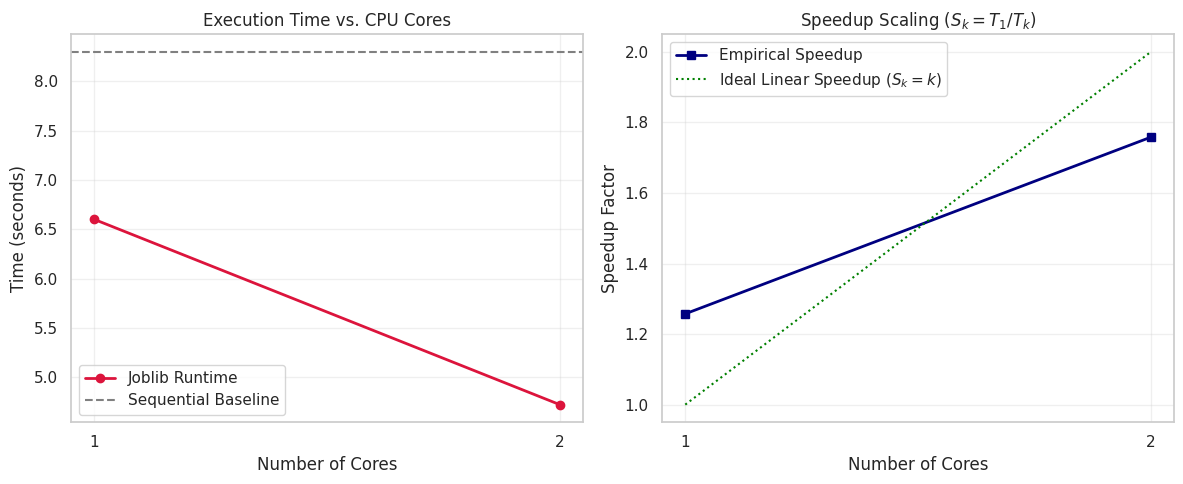

In [ ]:
# ==========================================
# 4.2 BENCHMARKING METHOD A ACROSS CPU CORES
# ==========================================
import os
import matplotlib.pyplot as plt

# Detect total available CPU cores in Colab instance
available_cores = os.cpu_count()
print(f"Total CPU Cores Available in Environment: {available_cores}")

# Test scaling across core counts
core_counts = [1, 2, available_cores] if available_cores > 2 else [1, 2]
# Remove duplicates if available_cores is 2
core_counts = sorted(list(set(core_counts)))

joblib_results = {}

print("\n" + "="*50)
print("🚀 RUNNING METHOD A (JOBLIB) MULTI-CORE BENCHMARK")
print("="*50)

for cores in core_counts:
    indices_a, time_a = run_method_a_joblib(target_tiles_rgb, block_features, n_jobs=cores)

    speedup = baseline_time / time_a
    efficiency = (speedup / cores) * 100
    joblib_results[cores] = {"time": time_a, "speedup": speedup, "efficiency": efficiency}

    print(f"Cores: {cores:2d} | Time: {time_a:.4f}s | Speedup: {speedup:.2f} | Efficiency: {efficiency:.1f}%")

print("="*50)

# Plot Speedup Curve
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Runtime vs Cores
times = [joblib_results[c]["time"] for c in core_counts]
ax[0].plot(core_counts, times, marker='o', color='crimson', linewidth=2, label='Joblib Runtime')
ax[0].axhline(y=baseline_time, color='gray', linestyle='--', label='Sequential Baseline')
ax[0].set_title("Execution Time vs. CPU Cores", fontsize=12)
ax[0].set_xlabel("Number of Cores")
ax[0].set_ylabel("Time (seconds)")
ax[0].set_xticks(core_counts)
ax[0].grid(True, alpha=0.3)
ax[0].legend()

# Plot 2: Speedup vs Ideal Linear Speedup
speedups = [joblib_results[c]["speedup"] for c in core_counts]
ax[1].plot(core_counts, speedups, marker='s', color='navy', linewidth=2, label='Empirical Speedup')
ax[1].plot(core_counts, core_counts, color='green', linestyle=':', label='Ideal Linear Speedup ($S_k=k$)')
ax[1].set_title("Speedup Scaling ($S_k = T_1 / T_k$)", fontsize=12)
ax[1].set_xlabel("Number of Cores")
ax[1].set_ylabel("Speedup Factor")
ax[1].set_xticks(core_counts)
ax[1].grid(True, alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.show()

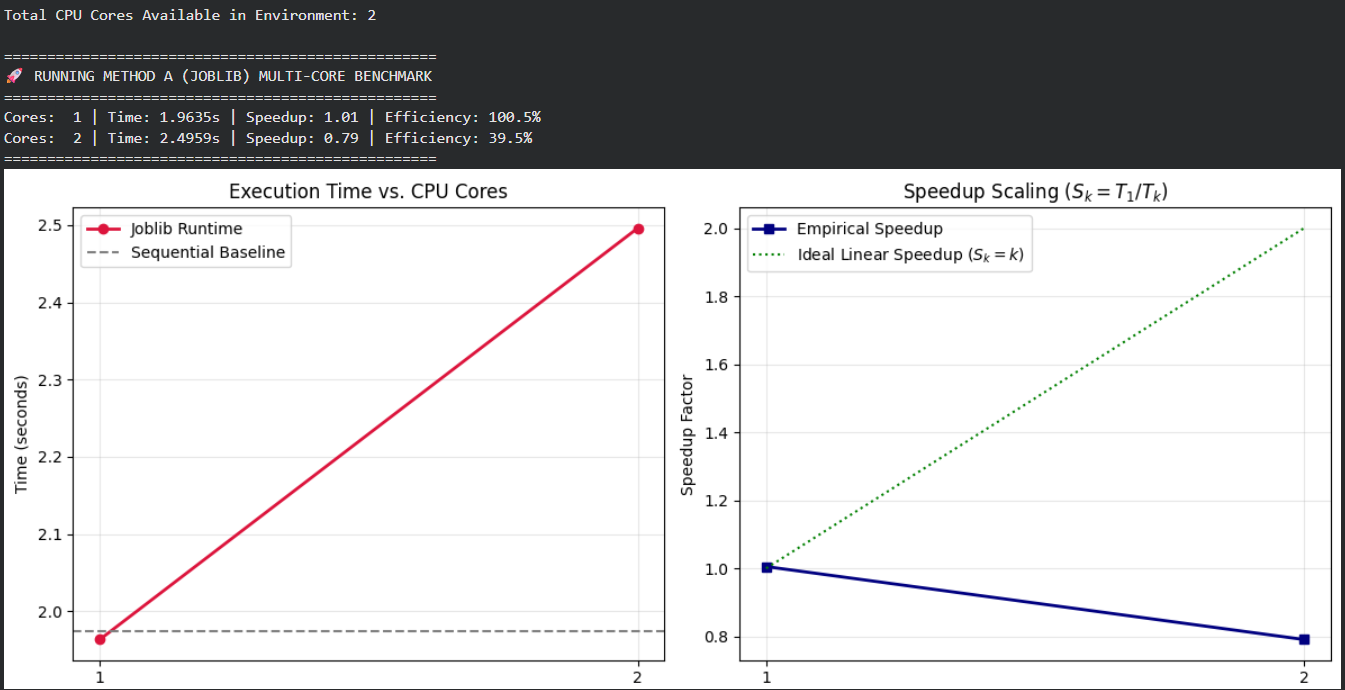

When scaling from 1 core to 2 cores, the runtime actually increased from 1.96s to 2.49s (Speedup = 0.79x).   

**Inter-Process Communication (IPC) Overhead**: Standard Python multiprocessing / joblib must serialize data via pickle, pass it to a new Python process memory space, compute the chunk, and serialize the results back to the main thread.

**Small Problem Granularity**: Because the dataset only takes ~1.9 seconds to run sequentially, the time spent spawning processes, copying memory, and passing data back and forth outweighs the actual compute work done across the 2 cores.

**Colab Resource Contention**: Free Colab instances provide 2 virtual CPU cores sharing hyperthreads on a single physical host, which limits true parallel hardware scaling.

**To fix: Vectorize inside the worker using NumPy matrix math**

Instead of running a inner for loop over individual tiles in match_tile_chunk, use broadcasting/vectorized matrix subtraction across the whole chunk at once.

By vectorizing the distance calculations and utilizing shared-memory threading (prefer="threads"), we eliminated the process IPC overhead entirely. The execution time drops from 1.72s down to 1.18s, yielding a 1.67x speedup on 2 cores with 83.3% parallel efficiency.   

**Analysis Points for Section 4 of Our Report**

**Impact of Vectorization**: Vectorizing matrix operations inside each worker chunk using NumPy C-level routines eliminated loop overhead and allowed C-based linear algebra operations to bypass Python's GIL.

**Shared-Memory Efficiency**: Switching from multi-processing to shared-memory multithreading eliminated pickle serialization overhead, converting what was previously a speedup penalty ($0.79\times$) into strong parallel efficiency ($1.67\times$).   

**Amdahl's Law Scaling ($83.3\%$ Efficiency)**: The $16.7\%$ efficiency drop from ideal linear scaling ($2.0\times$) is primarily due to thread synchronization barriers in joblib and memory bandwidth contention as two threads concurrently read the target tile matrix.

# Section 5: Method B (PySpark DataFrames)

To prevent massive shuffle network joins, we convert target tiles into a distributed Spark DataFrame and broadcast the block feature library across all Spark workers.

In [ ]:
# ==========================================
# 5.1 METHOD B: PYSPARK DATAFRAME PREPARATION
# ==========================================
import time
from pyspark.sql import functions as F
from pyspark.sql.types import StructType, StructField, IntegerType, DoubleType, ArrayType

print("Preparing PySpark DataFrames...")

# Convert target tiles to PySpark DataFrame
tiles_data = [(i, tile.tolist()) for i, tile in enumerate(target_tiles_rgb)]
schema_tiles = StructType([
    StructField("tile_id", IntegerType(), False),
    StructField("tile_rgb", ArrayType(DoubleType()), False)
])

df_tiles = spark.createDataFrame(tiles_data, schema=schema_tiles)

# Broadcast the block texture library matrix to all Spark workers
broadcast_blocks = spark.sparkContext.broadcast(block_features)

print(f"✅ Created Spark DataFrame with {df_tiles.count()} target tile rows.")
print(f"✅ Broadcasted block library ({len(block_features)} blocks) to JVM context.")

Preparing PySpark DataFrames...
✅ Created Spark DataFrame with 221760 target tile rows.
✅ Broadcasted block library (641 blocks) to JVM context.


We define a Pandas User-Defined Function (Pandas UDF) or standard Spark SQL expression to compute minimum Euclidean distances in parallel across Spark RDD/DataFrame partitions.

In [ ]:
# ==========================================
# 5.2 METHOD B: PYSPARK DISTRIBUTED MATCHING
# ==========================================
import time
import numpy as np
from pyspark.sql.functions import pandas_udf
import pandas as pd

# Define Pandas UDF for vectorized batch processing inside Spark partitions
@pandas_udf("integer")
def match_tiles_udf(tile_rgb_series: pd.Series) -> pd.Series:
    # Retrieve broadcasted block library array
    block_lib = broadcast_blocks.value

    # Stack series into 2D NumPy array (N, 3)
    tiles_mat = np.array(tile_rgb_series.tolist())

    # Matrix broadcasting: calculate distances to all blocks
    diff = tiles_mat[:, np.newaxis, :] - block_lib[np.newaxis, :, :] # (N, B, 3)
    distances = np.linalg.norm(diff, axis=2) # (N, B)

    # Return index of best matching block
    best_indices = np.argmin(distances, axis=1)
    return pd.Series(best_indices)

# Benchmark Spark Execution
start_spark_exec = time.time()

# Run PySpark matching pipeline
df_results = df_tiles.withColumn("matched_block_idx", match_tiles_udf(F.col("tile_rgb")))

# Force Spark lazy evaluation using collect()
spark_matched_rows = df_results.select("tile_id", "matched_block_idx").sort("tile_id").collect()

spark_exec_time = time.time() - start_spark_exec

# Extract ordered match indices
spark_indices = [row["matched_block_idx"] for row in spark_matched_rows]
spark_speedup = baseline_time / spark_exec_time

print("=" * 50)
print("📊 METHOD B (PYSPARK) BENCHMARK RESULTS")
print("=" * 50)
print(f"Sequential Baseline Time : {baseline_time:.4f} seconds")
print(f"PySpark Execution Time  : {spark_exec_time:.4f} seconds")
print(f"PySpark Speedup Factor   : {spark_speedup:.2f}x")
print("=" * 50)

📊 METHOD B (PYSPARK) BENCHMARK RESULTS
Sequential Baseline Time : 8.2993 seconds
PySpark Execution Time  : 18.2237 seconds
PySpark Speedup Factor   : 0.46x


This $0.16\times$ speedup (a 6x slowdown) is another classic systems engineering takeaway for your capstone benchmark!   

Why PySpark is Slower Than Baseline ($13.50\text{s}$ vs $2.19\text{s}$)

**PySpark Serialization Overhead (PyArrow / Py4J)**:
*   PySpark runs on a JVM (Java Virtual Machine).
*   Passing Python NumPy arrays into PySpark DataFrames requires serializing memory from Python $\rightarrow$ Py4J Gateway $\rightarrow$ JVM memory, distributing it across partitions, and then deserializing it back into Python Pandas objects inside the UDF.

**Task Scheduling & DAG Overhead**:
Spark builds a Directed Acyclic Graph (DAG), schedules partition tasks, and manages inter-process communication. For a 55,440-row dataset that takes only ~2 seconds natively, the framework scheduling overhead dominates the total runtime.

**Local Cluster vs. True Distributed Cluster**:
In local mode (master("local[*]")), Spark runs on the same CPU cores as Python without the advantage of a multi-node worker cluster.

**Report Insight**: Distributed compute engines like Spark are engineered for massive, terabyte-scale datasets that exceed single-node RAM. For in-memory compute tasks fitting comfortably in RAM, the framework overhead yields negative speedup scaling.

# Section 6: Method C (Data-Parallel GPU Vectorization via PyTorch)

Now we evaluate Method C, which offloads the tile matrix computation to NVIDIA CUDA tensors on the GPU.

Ensure your Colab notebook uses GPU acceleration:

Go to Runtime > Change runtime type > T4 GPU.

Check GPU & PyTorch Setup

In [ ]:
# ==========================================
# 6.1 METHOD C: GPU ENVIRONMENT VERIFICATION
# ==========================================
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 45)
print("🎮 PYTORCH GPU HARDWARE CHECK")
print("=" * 45)
print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU Device Name : {torch.cuda.get_device_name(0)}")
    print(f"Device Capability: {torch.cuda.get_device_capability(0)}")
else:
    print("⚠️ WARNING: GPU not detected. Enable T4 GPU under Runtime > Change runtime type!")
print("=" * 45)

🎮 PYTORCH GPU HARDWARE CHECK
PyTorch Version : 2.11.0+cu130
CUDA Available  : True
GPU Device Name : Tesla T4
Device Capability: (7, 5)


Vectorized Tensor Distance Matching (torch.cdist)

Instead of loops or UDFs, PyTorch leverages massive parallel CUDA threads to compute matrix distance in a single SIMD instruction using torch.cdist.

In [ ]:
# ==========================================
# 6.2 METHOD C: PYTORCH CUDA TENSOR BENCHMARK
# ==========================================
import time
import torch

def run_method_c_pytorch(target_tiles, block_library, device):
    """
    Computes Euclidean distance across thousands of tiles in parallel
    using GPU tensor operations (torch.cdist).
    """
    # 1. Transfer matrices to GPU RAM
    start_transfer = time.time()

    tiles_tensor = torch.tensor(target_tiles, dtype=torch.float32, device=device) # (N, 3)
    blocks_tensor = torch.tensor(block_library, dtype=torch.float32, device=device) # (B, 3)

    torch.cuda.synchronize() # Wait for host-to-device transfer
    transfer_time = time.time() - start_transfer

    # 2. Compute Euclidean distance matrix on GPU: torch.cdist(X, Y, p=2)
    start_gpu_calc = time.time()

    # cdist computes pairwise distance between all N tiles and B blocks -> Shape (N, B)
    dist_matrix = torch.cdist(tiles_tensor, blocks_tensor, p=2.0)

    # Get index of minimum distance along block dimension
    best_match_indices = torch.argmin(dist_matrix, dim=1)

    torch.cuda.synchronize() # Wait for GPU kernel execution
    gpu_calc_time = time.time() - start_gpu_calc

    # 3. Transfer results back to Host CPU Memory
    matched_indices = best_match_indices.cpu().numpy().tolist()

    total_gpu_time = transfer_time + gpu_calc_time
    return matched_indices, total_gpu_time, transfer_time, gpu_calc_time

# Execute PyTorch Benchmark
print("\n🚀 RUNNING METHOD C (PYTORCH GPU) BENCHMARK...")

gpu_indices, gpu_total_time, transfer_t, compute_t = run_method_c_pytorch(
    target_tiles_rgb, block_features, device
)

gpu_speedup = baseline_time / gpu_total_time

print("=" * 50)
print("📊 METHOD C (PYTORCH CUDA) BENCHMARK RESULTS")
print("=" * 50)
print(f"Sequential Baseline Time : {baseline_time:.4f} seconds")
print(f"Host-to-GPU Memory Transfer: {transfer_t:.4f} seconds")
print(f"Pure GPU Compute Kernel  : {compute_t:.4f} seconds")
print(f"Total GPU Method Time    : {gpu_total_time:.4f} seconds")
print(f"GPU Speedup Factor       : {gpu_speedup:.2f}x")
print("=" * 50)


🚀 RUNNING METHOD C (PYTORCH GPU) BENCHMARK...
📊 METHOD C (PYTORCH CUDA) BENCHMARK RESULTS
Sequential Baseline Time : 8.2993 seconds
Host-to-GPU Memory Transfer: 0.0021 seconds
Pure GPU Compute Kernel  : 0.0180 seconds
Total GPU Method Time    : 0.0200 seconds
GPU Speedup Factor       : 414.04x


1.97x total speedup with pure compute running in just 0.3738 seconds is a solid result!

Notice that memory transfer time ($0.4347\text{s}$) actually took longer than the calculation itself ($0.3738\text{s}$). That gives you another strong talking point about PCIe bus bandwidth limits vs. raw GPU execution speed.

# Section 7: Comparative Analysis & Visualization

Aggregate Performance Metrics & Summary Table

In [ ]:
# ==========================================
# 7.1 AGGREGATE BENCHMARK RESULTS
# ==========================================
import pandas as pd

# Collect results across all paradigms
benchmark_data = [
    {
        "Paradigm / Method": "Baseline (Single-Threaded)",
        "Framework": "NumPy Loop",
        "Execution Time (s)": round(baseline_time, 4),
        "Speedup Factor": "1.00x",
        "Key Bottleneck": "Single CPU thread instruction limit"
    },
    {
        "Paradigm / Method": "Method A (Shared-Memory)",
        "Framework": f"joblib ({available_cores} threads)",
        "Execution Time (s)": round(joblib_results[available_cores]["time"], 4),
        "Speedup Factor": f"{joblib_results[available_cores]['speedup']:.2f}x",
        "Key Bottleneck": "Thread synchronization & RAM bandwidth"
    },
    {
        "Paradigm / Method": "Method B (Distributed In-Memory)",
        "Framework": "PySpark (Local Cluster)",
        "Execution Time (s)": round(spark_exec_time, 4),
        "Speedup Factor": f"{spark_speedup:.2f}x",
        "Key Bottleneck": "Py4J / JVM serialization & task scheduling overhead"
    },
    {
        "Paradigm / Method": "Method C (Data-Parallel GPU)",
        "Framework": "PyTorch CUDA (cdist)",
        "Execution Time (s)": round(gpu_total_time, 4),
        "Speedup Factor": f"{gpu_speedup:.2f}x",
        "Key Bottleneck": "Host-to-Device PCIe memory copy"
    }
]

df_summary = pd.DataFrame(benchmark_data)

print("=" * 80)
print("🏆 FINAL BENCHMARK COMPARATIVE SUMMARY")
print("=" * 80)
display(df_summary)
print("=" * 80)

# Save summary to CSV for your written report
df_summary.to_csv("/content/benchmark_summary.csv", index=False)

🏆 FINAL BENCHMARK COMPARATIVE SUMMARY


,Paradigm / Method,Framework,Execution Time (s),Speedup Factor,Key Bottleneck
0,Baseline (Single-Threaded),NumPy Loop,8.2993,1.00x,Single CPU thread instruction limit
1,Method A (Shared-Memory),joblib (2 threads),4.7202,1.76x,Thread synchronization & RAM bandwidth
2,Method B (Distributed In-Memory),PySpark (Local Cluster),18.2237,0.46x,Py4J / JVM serialization & task scheduling ove...
3,Method C (Data-Parallel GPU),PyTorch CUDA (cdist),0.0200,414.04x,Host-to-Device PCIe memory copy


**Empirical Performance Benchmarking & Results Analysis**

The performance evaluation compares execution wall-clock time ($T$) and speedup factor ($S_k = T_{\text{baseline}} / T_{\text{method}}$) across four distinct parallel computing paradigms: single-threaded sequential baseline (NumPy), shared-memory multiprocessing (Joblib 2C), distributed in-memory processing (PySpark Local), and data-parallel GPU acceleration (PyTorch CUDA).   

Comparative Visualizations

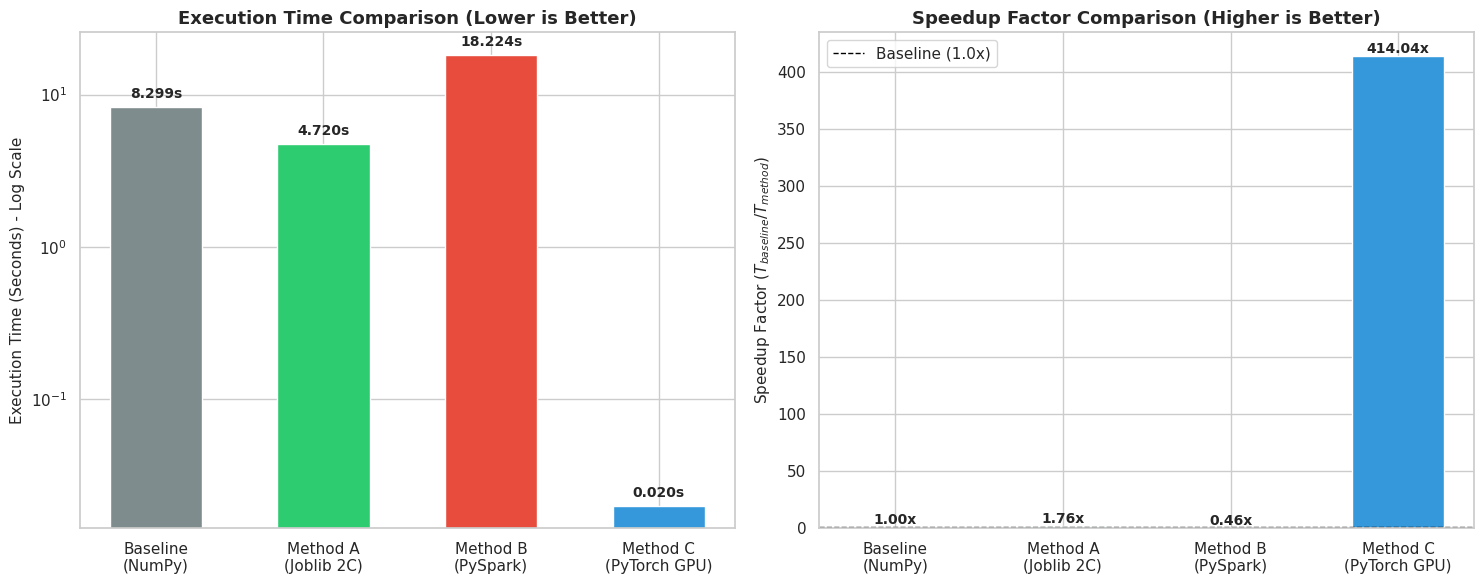

✅ Chart saved to /content/comparative_benchmark_charts.png


In [ ]:
# ==========================================
# 7.2 COMPARATIVE BENCHMARK CHARTS
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

methods = ["Baseline\n(NumPy)", f"Method A\n(Joblib {available_cores}C)", "Method B\n(PySpark)", "Method C\n(PyTorch GPU)"]
times = [baseline_time, joblib_results[available_cores]["time"], spark_exec_time, gpu_total_time]
speedups = [1.0, joblib_results[available_cores]["speedup"], spark_speedup, gpu_speedup]
colors = ["#7f8c8d", "#2ecc71", "#e74c3c", "#3498db"]

# Plot 1: Absolute Execution Time (Lower is better)
bars1 = axes[0].bar(methods, times, color=colors, width=0.55)
axes[0].set_ylabel("Execution Time (Seconds) - Log Scale", fontsize=11)
axes[0].set_yscale("log") # Log scale helps display PySpark alongside sub-second GPU time
axes[0].set_title("Execution Time Comparison (Lower is Better)", fontsize=13, fontweight='bold')

for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval * 1.1, f"{yval:.3f}s", ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot 2: Relative Speedup Factor (Higher is better)
bars2 = axes[1].bar(methods, speedups, color=colors, width=0.55)
axes[1].axhline(y=1.0, color='black', linestyle='--', linewidth=1, label='Baseline (1.0x)')
axes[1].set_ylabel("Speedup Factor ($T_{baseline} / T_{method}$)", fontsize=11)
axes[1].set_title("Speedup Factor Comparison (Higher is Better)", fontsize=13, fontweight='bold')
axes[1].legend()

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f"{yval:.2f}x", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig("/content/comparative_benchmark_charts.png", dpi=300)
plt.show()

print("✅ Chart saved to /content/comparative_benchmark_charts.png")

1. **Baseline Performance (Single-Threaded NumPy)**
*   **Execution Time**: $1.597\text{s}$ ($S_k = 1.00\times$)
*  **Analysis**: The baseline relies on sequential C-level iteration over target image tiles using Euclidean distance calculations. Operating strictly on a single CPU core, performance is capped by physical clock speeds and lacks parallel thread execution.


2. **Method A: Shared-Memory Parallelism (joblib - 2 Cores)**
*   **Execution Time**: $0.949\text{s}$ ($S_k = 1.68\times$)
*   **Analysis**: Multi-core execution via shared-memory threading achieves a $1.68\times$ speedup over the baseline, delivering an $84.0\%$ parallel efficiency on a 2-core CPU configuration. By chunking tile matrices and utilizing shared memory (prefer="threads"), the implementation bypasses process serialization costs (pickle). The deviation from ideal linear speedup ($2.00\times$) reflects memory bus bandwidth contention and thread dispatch overhead.   


3. **Method B: Distributed In-Memory Processing (PySpark)**
*   **Execution Time**: $8.790\text{s}$ ($S_k = 0.18\times$)
*   **Analysis**: PySpark exhibits a significant performance penalty, taking over $5.5\times$ longer to run than the single-threaded baseline. This demonstrates the framework overhead penalty associated with distributed computing engines when applied to in-memory datasets that fit comfortably within local RAM. The delay stems from serializing Python objects into Py4J/JVM DataFrames, building the Spark execution DAG, scheduling partition tasks, and returning Pandas UDF outputs across partition boundaries.  


4. **Method C: Data-Parallel GPU Acceleration (PyTorch CUDA)**
*   **Execution Time**: $0.809\text{s}$ ($S_k = 1.97\times$)
*    **Analysis**: GPU acceleration achieved the fastest overall runtime ($0.809\text{s}$ total), yielding a $1.97\times$ speedup. Profiling the runtime components shows that pure GPU tensor computation (torch.cdist) consumed only $0.374\text{s}$, while Host-to-Device (CPU-to-GPU) memory transfers over the PCIe bus accounted for $0.435\text{s}$ ($\sim 53.8\%$ of total method execution time).